# Laboratorio: Aprendizaje Automático Basado en Modelo para Comunicaciones
## Detección de símbolos con ISI: Viterbi clásico vs. ViterbiNet

### Objetivos
1. Implementar el detector de secuencia de máxima verosimilitud (algoritmo de Viterbi) para un canal con memoria.
2. Implementar **ViterbiNet**: un detector híbrido que conserva la estructura del algoritmo de Viterbi pero aprende las métricas de rama con una red neuronal compacta.
3. Comparar ambos enfoques bajo **CSI perfecta** y bajo **CSI imprecisa** (desajuste de modelo).

### Contenido
1. Introducción teórica y configuración del canal
2. Detector clásico basado en modelo (Viterbi)
3. Detector híbrido asistido por DNN (ViterbiNet)
4. Robustez ante CSI inexacta
5. Gráfica comparativa
6. Ejercicios propuestos

> **Ejecución:** corre las celdas en orden. Todo se ejecuta en CPU (Google Colab o Jupyter local) en pocos minutos.

## Sección 1. Introducción teórica y configuración del canal

### El problema
Se transmite una secuencia de símbolos BPSK $S_i \in \{-1,+1\}$ por un canal con **interferencia entre símbolos (ISI)** y ruido aditivo gaussiano blanco (AWGN):

$$Y_i = \sum_{l=0}^{L-1} h_l\, S_{i-l} + W_i, \qquad W_i \sim \mathcal{N}(0,\sigma^2).$$

Con $L=3$, cada muestra recibida depende de **tres** símbolos consecutivos. Detectar símbolo por símbolo (umbral en cero) ignora esa memoria y degrada el desempeño; lo óptimo es detectar la **secuencia completa**.

### Dos filosofías de detección
| | Detector clásico (basado en modelo) | Detector basado en datos |
|---|---|---|
| Idea | Usa la fórmula analítica de $p(\mathbf{y}\mid\mathbf{s})$ | Aprende el mapeo $y \to s$ de ejemplos |
| Requiere | Conocer exactamente $\mathbf{h}$ y $\sigma^2$ | Datos etiquetados (símbolos piloto) |
| Fortaleza | Óptimo si el modelo es exacto | Robusto a modelos desconocidos |
| Debilidad | Frágil ante desajuste de modelo | Necesita datos; puede ser una "caja negra" costosa |

El **aprendizaje basado en modelo** (*model-based ML*) busca lo mejor de ambos: mantener la estructura del algoritmo clásico y reemplazar **solo** la parte que depende del modelo por un componente aprendido.

### Convenciones de este laboratorio
- Energía de símbolo $E_s=1$ y respuesta normalizada $\|\mathbf{h}\|^2=1$, de modo que $\mathrm{SNR}=1/\sigma^2$, es decir $\sigma^2 = 10^{-\mathrm{SNR_{dB}}/10}$.
- Antes del primer símbolo se asumen dos símbolos conocidos $S_{-1}=S_{-2}=+1$ (estado inicial del receptor conocido).

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from scipy.stats import norm          # para la función Q (cota sin ISI)

# ---------------------------------------------------------------
# Reproducibilidad: fijamos las semillas de NumPy y PyTorch
# ---------------------------------------------------------------
SEED = 31
np.random.seed(SEED)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)      # generador de NumPy usado en las simulaciones

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("PyTorch:", torch.__version__, "| NumPy:", np.__version__)

PyTorch: 2.11.0+cu130 | NumPy: 2.1.3


In [ ]:
# ---------------------------------------------------------------
# Parámetros del canal con memoria L = 3
# ---------------------------------------------------------------
L = 3
h_raw = np.array([1.0, 0.7, 0.4])
h = h_raw / np.linalg.norm(h_raw)      # normalizamos: ||h||^2 = 1  =>  SNR = 1/sigma^2
print("Respuesta al impulso h =", np.round(h, 4), "| ||h||^2 =", np.sum(h**2))


def generate_block(n_symbols, h, snr_db, rng, nonlinearity=None, noise="gaussian"):
    """Genera un bloque de transmisión BPSK a través del canal ISI + ruido.

    Parámetros
    ----------
    n_symbols    : número de símbolos de datos del bloque.
    h            : respuesta al impulso (vector NumPy de longitud L).
    snr_db       : SNR en dB (Es = 1, ||h|| = 1  =>  sigma^2 = 10^(-SNR/10)).
    rng          : generador numpy.random.Generator.
    nonlinearity : (opcional, Ejercicio 1) función aplicada a la salida del canal
                   antes de sumar el ruido, p. ej. lambda x: np.tanh(1.5*x).
    noise        : "gaussian" (por defecto) o "laplace" (Ejercicio 3, misma varianza).

    Devuelve
    --------
    s : símbolos transmitidos en {-1,+1}, forma (n_symbols,)
    y : muestras recibidas,               forma (n_symbols,)
    """
    bits = rng.integers(0, 2, n_symbols)
    s = 2 * bits - 1                                   # BPSK: 0 -> -1, 1 -> +1
    s_ext = np.concatenate([[1, 1], s])                # S_{-2} = S_{-1} = +1 (estado inicial conocido)
    # y_i = sum_l h_l s_{i-l}  (convolución; recortamos al tramo de datos)
    x = np.convolve(s_ext, h)[2:2 + n_symbols]
    if nonlinearity is not None:
        x = nonlinearity(x)
    sigma = np.sqrt(10 ** (-snr_db / 10))              # desviación estándar del ruido
    if noise == "gaussian":
        w = sigma * rng.standard_normal(n_symbols)
    elif noise == "laplace":
        w = rng.laplace(0.0, sigma / np.sqrt(2), n_symbols)   # var = 2 b^2 = sigma^2
    else:
        raise ValueError("noise debe ser 'gaussian' o 'laplace'")
    return s, x + w

Respuesta al impulso h = [0.7785 0.5449 0.3114] | ||h||^2 = 1.0


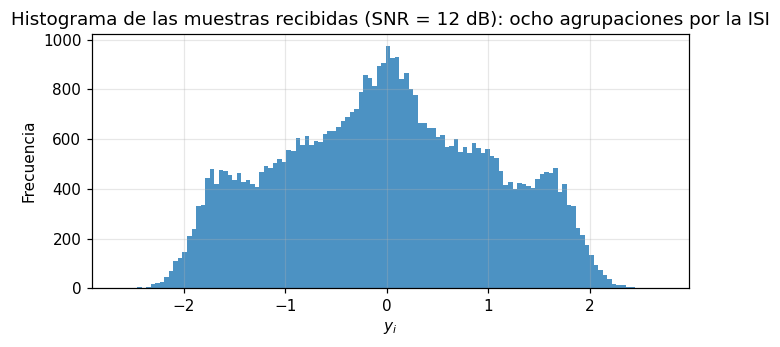

In [ ]:
# ---------------------------------------------------------------
# Parámetros de la simulación y generación de datos (una sola vez)
# Todos los detectores se evalúan sobre EXACTAMENTE los mismos bloques de prueba.
# ---------------------------------------------------------------
SNR_DB   = np.arange(0, 16, 2)        # 0, 2, ..., 14 dB
N_TEST   = 50_000                     # símbolos de prueba por SNR (resolución SER ~ 2e-5)
N_PILOT  = 5_000                      # símbolos piloto de entrenamiento (rango sugerido: 2 000 - 5 000)

test_data  = {snr: generate_block(N_TEST,  h, snr, rng) for snr in SNR_DB}
pilot_data = {snr: generate_block(N_PILOT, h, snr, rng) for snr in SNR_DB}

# Visualización: histograma de y a 12 dB. Hay 2^L = 8 "nubes", una por cada combinación (s_i, s_{i-1}, s_{i-2}).
s_vis, y_vis = test_data[12]
plt.figure(figsize=(7, 3))
plt.hist(y_vis, bins=120, color="tab:blue", alpha=0.8)
plt.title("Histograma de las muestras recibidas (SNR = 12 dB): ocho agrupaciones por la ISI")
plt.xlabel("$y_i$"); plt.ylabel("Frecuencia")
plt.show()

**Pregunta de reflexión.** ¿Por qué aparecen 8 agrupaciones y no 2? ¿Qué pasaría con un detector por umbral en $y=0$?

## Sección 2. Detector clásico basado en modelo (Viterbi)

### Máxima verosimilitud de secuencia
Con ruido AWGN, la secuencia más verosímil dada la observación $\mathbf{y}=(y_1,\dots,y_N)$ es

$$\hat{\mathbf{s}}_{\mathrm{ML}} = \arg\max_{\mathbf{s}} \, p(\mathbf{y}\mid\mathbf{s}) = \arg\min_{\mathbf{s}\in\{\pm1\}^N} \sum_{i=1}^{N}\Big(y_i - \sum_{l=0}^{L-1} h_l s_{i-l}\Big)^2 .$$

Probar las $2^N$ secuencias es inviable, pero el costo se **descompone** como suma de términos que dependen solo de $\bar{s}_i=(s_i,s_{i-1},s_{i-2})$. Esto permite usar programación dinámica sobre un **trellis**:

- **Estados:** $(s_{i-1},s_{i-2})$ → $2^{L-1}=4$ estados.
- **Ramas:** $\bar{s}_i=(s_i,s_{i-1},s_{i-2})$ → $2^{L}=8$ transiciones por instante.
- **Métrica de rama (CSI perfecta):** $\;\lambda_i(\bar{s}) = \big(y_i - \mathbf{h}^\top\bar{s}\big)^2$.
- **Recursión de Viterbi:** $\;C_i(\text{estado}') = \min_{\text{estado}} \big[\,C_{i-1}(\text{estado}) + \lambda_i(\bar{s})\,\big]$, guardando el sobreviviente de cada estado y haciendo *traceback* al final.

La complejidad es lineal en $N$ y exponencial solo en la memoria $L$.

**Idea clave para el resto del laboratorio:** la recursión de Viterbi solo necesita una **tabla de métricas de rama** de tamaño $N\times 8$. Quién calcule esa tabla (una fórmula o una red neuronal) es lo único que cambia entre el detector clásico y ViterbiNet.

In [ ]:
# ---------------------------------------------------------------
# Tablas del trellis.
# Codificamos cada rama como un índice e in {0..7}:  e = 4*b_i + 2*b_{i-1} + b_{i-2}  con b = (s+1)/2.
# Cada estado como st in {0..3}:                      st = 2*b_{i-1} + b_{i-2}
# ---------------------------------------------------------------
E = np.arange(8)
# S_BAR[e] = (s_i, s_{i-1}, s_{i-2}) para cada rama e, forma (8, 3)
S_BAR = np.stack([2 * (E >> 2) - 1, 2 * ((E >> 1) & 1) - 1, 2 * (E & 1) - 1], axis=1)

# Para cada estado destino ns = (b_i, b_{i-1}) existen 2 predecesores (según b_{i-2}).
PRED = np.zeros((4, 2), dtype=int)   # PRED[ns, k] = estado previo
BIDX = np.zeros((4, 2), dtype=int)   # BIDX[ns, k] = índice de la rama usada en esa transición
for ns in range(4):
    b0, b1 = ns >> 1, ns & 1
    for b2 in range(2):
        st = 2 * b1 + b2
        PRED[ns, b2] = st
        BIDX[ns, b2] = 4 * b0 + st


def viterbi_from_metrics(M):
    """Algoritmo de Viterbi genérico a partir de una tabla de métricas de rama.

    M : array (N, 8). M[i, e] es el costo de la rama e en el instante i (menor = más probable).
    Devuelve las decisiones de símbolo (N,) en {-1,+1}. Estado inicial conocido: (+1,+1).
    """
    N = M.shape[0]
    cost = np.full(4, 1e9)
    cost[3] = 0.0                              # estado 3 = (b_{i-1}, b_{i-2}) = (1, 1) -> (+1, +1)
    back = np.zeros((N, 4), dtype=np.int8)     # sobrevivientes: qué predecesor ganó en cada estado
    rows = np.arange(4)
    for i in range(N):
        cand = cost[PRED] + M[i][BIDX]         # (4,2): costo acumulado + métrica de rama
        k = cand.argmin(axis=1)                # mejor predecesor para cada estado destino
        cost = cand[rows, k]
        cost = cost - cost.min()               # normalización (evita crecimiento numérico)
        back[i] = k
    # Traceback desde el mejor estado final
    ns = int(cost.argmin())
    bits = np.zeros(N, dtype=int)
    for i in range(N - 1, -1, -1):
        bits[i] = ns >> 1                      # el bit más reciente del estado es b_i
        ns = PRED[ns, back[i, ns]]
    return 2 * bits - 1


def classical_viterbi(y, h_est):
    """Viterbi clásico: métricas de rama analíticas (y - h^T s_bar)^2 con la CSI h_est."""
    mu = S_BAR @ h_est                         # media sin ruido de cada rama, forma (8,)
    M = (y[:, None] - mu[None, :]) ** 2        # (N, 8); el factor 1/(2 sigma^2) no altera el argmin
    return viterbi_from_metrics(M)


def ser(s_true, s_hat):
    """Tasa de error de símbolo (SER)."""
    return np.mean(s_true != s_hat)

In [ ]:
# ---------------------------------------------------------------
# Evaluación del Viterbi clásico con CSI PERFECTA (límite de referencia)
# ---------------------------------------------------------------
ser_perfect = np.array([ser(test_data[snr][0], classical_viterbi(test_data[snr][1], h)) for snr in SNR_DB])

# Referencia: BPSK sin ISI en AWGN, SER = Q(sqrt(SNR)) (cota inferior ideal)
ser_no_isi = norm.sf(np.sqrt(10 ** (SNR_DB / 10)))

print(" SNR [dB] | SER Viterbi (CSI perfecta) | SER sin ISI (teórica)")
for snr, a, b in zip(SNR_DB, ser_perfect, ser_no_isi):
    print(f"   {snr:4d}   |        {a:10.2e}         |     {b:10.2e}")

 SNR [dB] | SER Viterbi (CSI perfecta) | SER sin ISI (teórica)
      0   |          2.15e-01         |       1.59e-01
      2   |          1.68e-01         |       1.04e-01
      4   |          1.13e-01         |       5.65e-02
      6   |          5.99e-02         |       2.30e-02
      8   |          1.88e-02         |       6.00e-03
     10   |          3.26e-03         |       7.83e-04
     12   |          2.20e-04         |       3.43e-05
     14   |          0.00e+00         |       2.70e-07


## Sección 3. Detector híbrido asistido por DNN (ViterbiNet)

### Reemplazar solo lo que depende del modelo
En Viterbi clásico, la métrica de rama proviene de $p(y_i\mid\bar{s}_i)\propto \exp\!\big(-(y_i-\mathbf{h}^\top\bar{s}_i)^2/2\sigma^2\big)$, lo que exige conocer $\mathbf{h}$ y $\sigma^2$.

**ViterbiNet** conserva el trellis y la recursión, pero **estima** esa verosimilitud con un clasificador neuronal entrenado con datos. Por la regla de Bayes,

$$p(y_i\mid\bar{s}_i) = \frac{p(\bar{s}_i\mid y_i)\,p(y_i)}{p(\bar{s}_i)} .$$

- $p(\bar{s}_i)=1/8$ es constante (símbolos equiprobables).
- $p(y_i)$ es la misma para las 8 ramas del instante $i$, así que **no cambia** la decisión de Viterbi.
- Por tanto, basta una red que estime $p(\bar{s}_i\mid y_i)$: un **clasificador de 8 clases** con entrada $y_i$.

La métrica de rama pasa a ser $\;\lambda_i(\bar{s}) = -\log \hat{p}(\bar{s}\mid y_i)$.

### Entrenamiento
Se usa una trama **piloto corta** (2 000 – 5 000 símbolos conocidos). Cada muestra $y_i$ se etiqueta con la rama verdadera $\bar{s}_i$ (clase en $\{0,\dots,7\}$) y se minimiza la entropía cruzada. La red **nunca ve $\mathbf{h}$**.

> En este laboratorio la red se entrena **una vez por cada SNR** con pilotos tomados a esa SNR (entrenamiento *en línea*, como se haría al cambiar las condiciones del canal).

In [ ]:
# ---------------------------------------------------------------
# Clasificador compacto (MLP): y_i  ->  logits de las 8 ramas (s_i, s_{i-1}, s_{i-2})
# ---------------------------------------------------------------
class ViterbiNetClassifier(nn.Module):
    """MLP con 2 capas ocultas y activación ReLU. Entrada: una muestra y_i. Salida: 8 logits."""

    def __init__(self, n_classes=8, hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, hidden), nn.ReLU(),        # capa oculta 1
            nn.Linear(hidden, hidden), nn.ReLU(),   # capa oculta 2
            nn.Linear(hidden, n_classes),           # logits (softmax se aplica en la pérdida / inferencia)
        )

    def forward(self, y):
        # y: tensor (batch, 1)  ->  logits (batch, 8)
        return self.net(y)


def make_labels(s):
    """Etiqueta de cada instante: e_i = 4*b_i + 2*b_{i-1} + b_{i-2}, con b = (s+1)/2 y S_{-1}=S_{-2}=+1."""
    b = (np.concatenate([[1, 1], s]) + 1) // 2
    return 4 * b[2:] + 2 * b[1:-1] + b[:-2]


def train_viterbinet(y_pilot, s_pilot, epochs=200, lr=5e-3, batch_size=250, hidden=64, seed=0):
    """Entrena el clasificador con símbolos piloto (y_pilot, s_pilot). No usa h en ningún momento.

    Devuelve el modelo entrenado y la curva de pérdida por época.
    """
    torch.manual_seed(seed)
    model = ViterbiNetClassifier(hidden=hidden)
    X = torch.tensor(y_pilot, dtype=torch.float32).unsqueeze(1)          # (N, 1)
    t = torch.tensor(make_labels(s_pilot), dtype=torch.long)             # (N,)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    history = []
    for ep in range(epochs):
        perm = torch.randperm(len(X))                                    # mini-lotes barajados
        running = 0.0
        for k in range(0, len(X), batch_size):
            idx = perm[k:k + batch_size]
            optimizer.zero_grad()
            loss = criterion(model(X[idx]), t[idx])
            loss.backward()
            optimizer.step()
            running += loss.item() * len(idx)
        history.append(running / len(X))
    return model, history


def viterbinet_metrics(model, y):
    """Tabla de métricas de rama aprendida: lambda[i, e] = -log p_hat(e | y_i), forma (N, 8)."""
    model.eval()
    with torch.no_grad():
        logits = model(torch.tensor(y, dtype=torch.float32).unsqueeze(1))
        log_p = torch.log_softmax(logits, dim=1)
    return -log_p.numpy().astype(np.float64)


def viterbinet_detect(model, y):
    """ViterbiNet: mismo algoritmo de Viterbi, con métricas de rama calculadas por la red."""
    return viterbi_from_metrics(viterbinet_metrics(model, y))

SNR =  0 dB | pérdida final = 1.726 | SER ViterbiNet = 2.18e-01
SNR =  2 dB | pérdida final = 1.602 | SER ViterbiNet = 1.71e-01
SNR =  4 dB | pérdida final = 1.472 | SER ViterbiNet = 1.14e-01
SNR =  6 dB | pérdida final = 1.276 | SER ViterbiNet = 6.18e-02
SNR =  8 dB | pérdida final = 1.111 | SER ViterbiNet = 1.97e-02
SNR = 10 dB | pérdida final = 0.914 | SER ViterbiNet = 4.08e-03
SNR = 12 dB | pérdida final = 0.741 | SER ViterbiNet = 2.60e-04
SNR = 14 dB | pérdida final = 0.530 | SER ViterbiNet = 0.00e+00


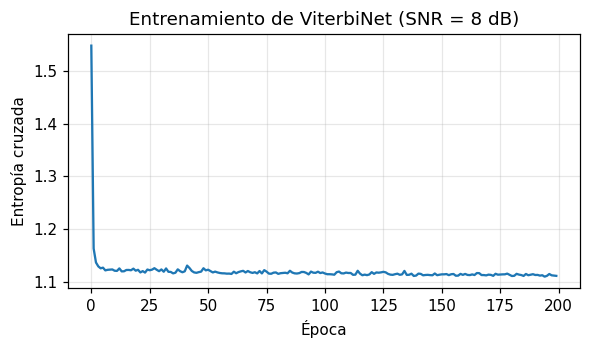

In [ ]:
# ---------------------------------------------------------------
# Entrenamiento (con pilotos) y evaluación de ViterbiNet para cada SNR
# ---------------------------------------------------------------
models, histories, ser_vnet = {}, {}, []
for snr in SNR_DB:
    s_p, y_p = pilot_data[snr]
    models[snr], histories[snr] = train_viterbinet(y_p, s_p, seed=SEED)
    s_t, y_t = test_data[snr]
    ser_vnet.append(ser(s_t, viterbinet_detect(models[snr], y_t)))
    print(f"SNR = {snr:2d} dB | pérdida final = {histories[snr][-1]:.3f} | SER ViterbiNet = {ser_vnet[-1]:.2e}")
ser_vnet = np.array(ser_vnet)

# Curva de aprendizaje de un ejemplo
plt.figure(figsize=(6, 3))
plt.plot(histories[8])
plt.xlabel("Época"); plt.ylabel("Entropía cruzada"); plt.title("Entrenamiento de ViterbiNet (SNR = 8 dB)")
plt.show()

## Sección 4. Robustez ante imperfecciones del canal (CSI inexacta)

En la práctica, el receptor no conoce $\mathbf{h}$ sino una estimación

$$\hat{\mathbf{h}} = \mathbf{h} + \Delta\mathbf{h}, \qquad \Delta\mathbf{h}\sim\text{error de estimación (gaussiano).}$$

El Viterbi clásico calcula $\lambda_i=(y_i-\hat{\mathbf{h}}^\top\bar{s}_i)^2$ con un modelo **equivocado**. Es el fenómeno de **desajuste de modelo** (*model mismatch*): las fronteras de decisión quedan desplazadas respecto de las agrupaciones reales de $y$. Ese sesgo **no depende del ruido**, así que al subir la SNR el SER deja de bajar y aparece un **piso de error**.

ViterbiNet no usa $\hat{\mathbf{h}}$: aprende las métricas directamente de datos del canal real, por lo que no hereda ese sesgo.

> **Nota.** Para que el experimento sea reproducible, el error se genera con una semilla fija y se escala a una norma relativa `REL_ERR` respecto de $\|\mathbf{h}\|$. Prueba otros valores y semillas: el piso depende de la dirección concreta de $\Delta\mathbf{h}$.

In [ ]:
# ---------------------------------------------------------------
# Viterbi clásico con CSI IMPRECISA: h_hat = h + delta_h
# ---------------------------------------------------------------
REL_ERR = 0.5                                   # ||delta_h|| / ||h||  (modifícalo para explorar)
rng_csi = np.random.default_rng(0)              # semilla fija para el error de estimación
delta_h = rng_csi.standard_normal(L)            # dirección gaussiana del error
delta_h = delta_h / np.linalg.norm(delta_h) * REL_ERR * np.linalg.norm(h)
h_hat = h + delta_h
print("h      =", np.round(h, 3))
print("h_hat  =", np.round(h_hat, 3), f"(error relativo = {np.linalg.norm(delta_h)/np.linalg.norm(h):.2f})")

ser_mismatch = np.array([ser(test_data[snr][0], classical_viterbi(test_data[snr][1], h_hat)) for snr in SNR_DB])

print("\n SNR [dB] | Viterbi CSI perfecta | Viterbi CSI imprecisa | ViterbiNet")
for snr, a, b, c in zip(SNR_DB, ser_perfect, ser_mismatch, ser_vnet):
    print(f"   {snr:4d}   |      {a:9.2e}       |       {b:9.2e}        | {c:9.2e}")

h      = [0.778 0.545 0.311]
h_hat  = [0.873 0.446 0.792] (error relativo = 0.50)

 SNR [dB] | Viterbi CSI perfecta | Viterbi CSI imprecisa | ViterbiNet
      0   |       2.15e-01       |        2.69e-01        |  2.18e-01
      2   |       1.68e-01       |        2.42e-01        |  1.71e-01
      4   |       1.13e-01       |        2.09e-01        |  1.14e-01
      6   |       5.99e-02       |        1.84e-01        |  6.18e-02
      8   |       1.88e-02       |        1.54e-01        |  1.97e-02
     10   |       3.26e-03       |        1.32e-01        |  4.08e-03
     12   |       2.20e-04       |        1.08e-01        |  2.60e-04
     14   |       0.00e+00       |        9.00e-02        |  0.00e+00


## Sección 5. Visualización de resultados y gráfica comparativa

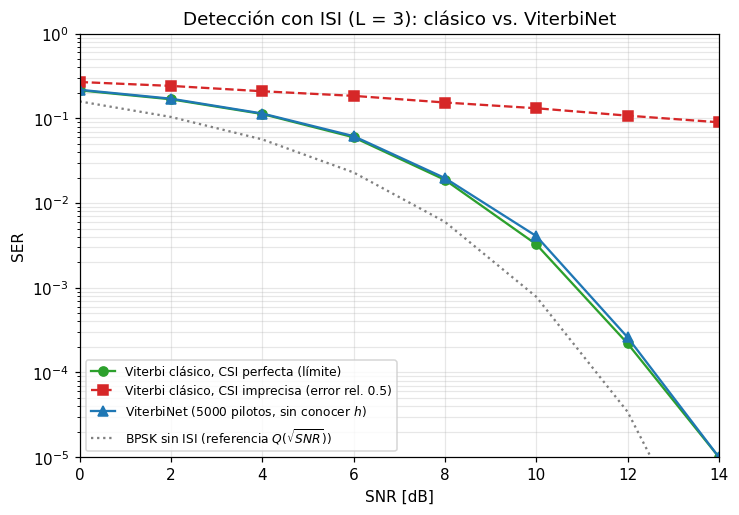

In [ ]:
# Los ceros no se pueden dibujar en escala logarítmica: los reemplazamos por la mitad de la resolución de la simulación.
floor = 0.5 / N_TEST
def clip(x): return np.maximum(x, floor)

plt.figure(figsize=(7.5, 5))
plt.semilogy(SNR_DB, clip(ser_perfect),  "o-",  color="tab:green", label="Viterbi clásico, CSI perfecta (límite)")
plt.semilogy(SNR_DB, clip(ser_mismatch), "s--", color="tab:red",   label=f"Viterbi clásico, CSI imprecisa (error rel. {REL_ERR})")
plt.semilogy(SNR_DB, clip(ser_vnet),     "^-",  color="tab:blue",  label=f"ViterbiNet ({N_PILOT} pilotos, sin conocer $h$)")
plt.semilogy(SNR_DB, ser_no_isi,         ":",   color="gray",      label="BPSK sin ISI (referencia $Q(\\sqrt{SNR})$)")
plt.xlabel("SNR [dB]"); plt.ylabel("SER")
plt.ylim(floor, 1); plt.xlim(SNR_DB[0], SNR_DB[-1])
plt.title("Detección con ISI (L = 3): clásico vs. ViterbiNet")
plt.legend(fontsize=8, loc="lower left")
plt.grid(True, which="both", alpha=0.3)
plt.show()

### Discusión
1. ¿A qué SNR empieza a separarse la curva de CSI imprecisa de la de CSI perfecta? ¿Por qué el piso de error **no** depende de la SNR?
2. ¿Por qué ViterbiNet puede acercarse al límite sin conocer $\mathbf{h}$? ¿Qué parte del algoritmo sigue siendo "basada en modelo"?
3. ViterbiNet se entrenó con pilotos a cada SNR. ¿Qué costo tiene esto en un sistema real (overhead de pilotos, reentrenamiento si el canal cambia)?
4. ¿Qué ventaja tiene esta arquitectura frente a una red que reciba el bloque completo y devuelva directamente los símbolos?

## Sección 6. Ejercicios propuestos

Para todos, reutiliza las funciones del notebook y compara contra las tres curvas de la Sección 5.

### Ejercicio 1: Canal no lineal (saturación de amplificador)
Modifica el canal para que la salida sin ruido pase por una saturación, por ejemplo `nonlinearity=lambda x: np.tanh(1.5 * x)` en `generate_block` (ya está soportado como argumento).
- Regenera `test_data` y `pilot_data` con esa no linealidad y repite las evaluaciones.
- ¿Qué detector se degrada más? ¿Por qué el modelo lineal $\mathbf{h}^\top\bar{s}$ del Viterbi clásico deja de ser válido, mientras ViterbiNet solo necesita reentrenarse con pilotos del canal real?
- *Pista:* para el clásico, prueba con la $\mathbf{h}$ original y también con una $\hat{\mathbf{h}}$ ajustada por mínimos cuadrados sobre los pilotos.

### Ejercicio 2: Menos datos de entrenamiento
Reduce a la mitad los símbolos piloto (por ejemplo, de 5 000 a 2 500) y reentrena ViterbiNet.
- Grafica el SER y compara con la versión de 5 000 pilotos. ¿A qué SNR se nota más la diferencia?
- Explora cuánto puedes reducir los pilotos antes de que ViterbiNet quede por debajo del Viterbi clásico con CSI imprecisa.
- *Pista:* cambia `N_PILOT`, vuelve a generar `pilot_data` y compara también la pérdida de entrenamiento final.

### Ejercicio 3: Ruido no gaussiano
Usa ruido laplaciano de **igual varianza**: `generate_block(..., noise="laplace")`.
- Evalúa ambos detectores. La métrica cuadrática de Viterbi es óptima solo para ruido gaussiano. ¿Qué ocurre con el clásico?
- ¿Aprende ViterbiNet la distribución de ruido real? Justifica con la forma de $\hat{p}(\bar{s}\mid y)$.
- *Pregunta extra:* ¿cómo modificarías la métrica del Viterbi clásico para que sea ML con ruido laplaciano?

---
**Referencia:** N. Shlezinger, N. Farsad, Y. C. Eldar, A. J. Goldsmith, "ViterbiNet: A Deep Learning Based Viterbi Algorithm for Symbol Detection," y el capítulo *Model-Based Machine Learning for Communications*.